# Refresher RP2: Induction and RF

**Part:** Physics refresher · **Reading time:** ~30 min · **Pass 1 overview:** [The MRI Scanner](../pass1_big_picture/P1.2_The_MRI_Scanner.ipynb) · **Refreshers you may want:** [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb), [Complex numbers & phasors](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

[RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb) showed that currents make magnetic fields. This refresher covers the reverse: **changing magnetic fields make voltages** (Faraday induction). That is how an MRI scanner *hears* the spins: the precessing magnetization is a tiny rotating magnet, and it induces a microvolt-level AC voltage in a nearby coil. Along the way we need alternating currents, resonance circuits (every RF coil is one), what "radio frequency" really means, why MRI coils work in the near field, and why induction also causes eddy currents, nerve stimulation and tissue heating.

## Learning goals

1. Define magnetic flux and use Faraday's and Lenz's laws to compute an induced voltage (EMF).
2. Explain why a rotating magnet near a coil induces an AC voltage whose amplitude grows with frequency, and estimate the size of the MRI signal.
3. Describe sinusoids with amplitude, frequency and phase, and use phasors/impedances for simple circuits.
4. Place MRI on the electromagnetic spectrum and explain why RF is non-ionizing.
5. Compute the resonance frequency, Q factor and bandwidth of an LC/RLC circuit — the basis of RF coils.
6. Explain near field vs radiation, the wavelength in tissue at 3 T and 7 T, eddy currents, and the reciprocity principle.

## Symbols used in this refresher

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec B$, $B$ | magnetic field (flux density) | T | |
| $B_0$ | main static field (along $z$) | T | 1.5, 3, 7 T |
| $B_1$ | RF magnetic field (perpendicular to $B_0$) | T | ~10 µT |
| $\hat B_1$ | field a coil makes **per ampere** of current ("coil sensitivity") | T/A | µT/A for a 10 cm loop |
| $\Phi$ | magnetic flux through a loop | Wb = T m² | |
| $A$ | area of a loop | m² | |
| $\theta$ | angle between the field and the loop normal (only in sec. 1) | rad | ⚠️ elsewhere: flip angle |
| $N_{turns}$ | number of turns of a coil | – | |
| $\mathcal E$ | electromotive force (EMF) = induced voltage | V | MRI: nV–mV |
| $t$ | time | s | |
| $f$, $\omega=2\pi f$ | frequency, angular frequency | Hz, rad/s | |
| $f_0$, $\omega_0$ | Larmor frequency $\bar\gamma B_0$ / $\gamma B_0$; also LC resonance frequency (sec. 6) | Hz, rad/s | 127.7 MHz at 3 T |
| $\bar\gamma$, $\gamma$ | gyromagnetic ratio | Hz/T, rad s⁻¹ T⁻¹ | 42.58 MHz/T, $2.675\times10^8$ for ¹H |
| $\vec m$, $m_0$ | magnetic (dipole) moment of a magnet or of a piece of magnetized tissue, its size | A m² = J/T | |
| $M_0$ | equilibrium magnetization of tissue | A/m | ≈ 9.3 mA/m for water at 3 T |
| $V_{vox}$ | voxel (or sample) volume | m³ | 1 mm³ = 10⁻⁹ m³ |
| $V_0$, $\varphi$ | amplitude and phase of a sinusoidal voltage | V, rad | |
| $\hat V$, $\hat I$ | complex amplitudes (phasors) of voltage and current | V, A | |
| $i$ | imaginary unit $\sqrt{-1}$ (engineers write $j$) | – | |
| $R$ | resistance | Ω | loaded coil: ~1–10 Ω |
| $L$ | inductance | H | 10 cm loop ≈ 0.25 µH |
| $C$ | capacitance | F | pF range at 128 MHz |
| $Z$ | impedance (complex "resistance" at frequency $\omega$) | Ω | |
| $Q$ | quality factor of a resonator | – | 10–500 |
| $\Delta f$ | bandwidth of a resonator (full width at half power) | Hz | $f_0/Q$ |
| $c$ | speed of light in vacuum | m/s | $3.0\times10^8$ |
| $\lambda$ | wavelength | m | 2.35 m in air, ≈ 26 cm in tissue at 128 MHz |
| $\varepsilon_r$ | relative permittivity (dielectric constant) | – | tissue ≈ 50–80 at 64–300 MHz |
| $h$ | Planck constant | J s | $6.626\times10^{-34}$ |
| $k_B$ | Boltzmann constant | J/K | $1.381\times10^{-23}$ |
| $T$ | absolute temperature (only in the noise estimate) | K | 310 K body |
| $E$ | electric field strength | V/m | |
| $\sigma_{el}$ | electrical conductivity of tissue | S/m | ≈ 0.5 S/m |
| $\rho$ | tissue density | kg/m³ | ≈ 1000 |
| $SAR$ | specific absorption rate (RF heating power per kg) | W/kg | limit 2 W/kg whole body |
| $r$ | radius of a current path in tissue | m | |
| $SR$ | gradient slew rate | T/m/s | 100–200 |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Magnetic flux

The **magnetic flux** through a loop measures "how much field passes through it":

$$\Phi = \int_{A} \vec B\cdot d\vec A \quad\overset{\text{uniform }B}{=}\quad B\,A\cos\theta .$$

In words: add up the component of $\vec B$ perpendicular to the loop over the loop's area. A loop facing the field head-on catches the most flux; a loop seen edge-on by the field catches none.
Where: $\Phi$ = flux [Wb = T m²], $d\vec A$ = small piece of the loop's area, as a vector perpendicular to the surface [m²], $A$ = total area [m²], $\theta$ = angle between $\vec B$ and the loop's normal.

Example: a 10 cm diameter loop ($A = 7.9\times10^{-3}$ m²) facing the Earth's field (50 µT) has $\Phi\approx4\times10^{-7}$ Wb.

## 2. Faraday's law and Lenz's law

Whenever the flux through a loop **changes**, a voltage appears around the loop:

$$\mathcal E = -N_{turns}\,\frac{d\Phi}{dt}.$$

In words: the induced voltage equals the rate of change of flux (times the number of turns, since every turn catches the flux). It does not matter *why* the flux changes: a moving magnet, a changing current in a nearby coil, or a rotating loop.
Where: $\mathcal E$ = electromotive force, the induced voltage around the loop [V]; $N_{turns}$ = number of turns; $d\Phi/dt$ = rate of change of the flux through one turn [Wb/s = V].

**Lenz's law** is the meaning of the minus sign: the induced voltage drives a current whose own magnetic field **opposes the change** of flux. Push a magnet into a coil and the coil pushes back; pull it out and the coil pulls. (If it were the other way round, the induced current would amplify the change, and you would get energy from nothing.)

**Numbers:** a 1 T field switched off in 1 s through a 10 cm loop gives $\mathcal E = 7.9\times10^{-3}$ V ≈ 8 mV per turn. The same change in 1 ms gives 8 V. Speed matters: $\mathcal E \propto d\Phi/dt$.

> **🔁 Refresher:** Faraday's law is a first-order derivative; the signals below are sinusoids whose derivative is again a sinusoid, scaled by $\omega$. See [ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb) and [complex numbers](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb).

## 3. A rotating magnet induces an AC voltage

This is the principle of every electrical generator and bicycle dynamo — and of MRI signal reception. A magnet rotating with angular frequency $\omega$ near a coil makes the flux through the coil go up and down sinusoidally, $\Phi(t) = \Phi_{max}\cos(\omega t)$, so

$$\mathcal E(t) = -N_{turns}\frac{d\Phi}{dt} = N_{turns}\,\Phi_{max}\,\omega\,\sin(\omega t).$$

In words: a rotating magnet induces an **alternating** (sinusoidal) voltage at the rotation frequency, with an amplitude **proportional to the rotation frequency** $\omega$ (spin it twice as fast → twice the voltage).
Where: $\Phi_{max}$ = largest flux through one turn [Wb], $\omega = 2\pi f$ = angular rotation frequency [rad/s].

In MRI the "rotating magnet" is the transverse magnetization $\vec M$ precessing at the Larmor frequency, as in the original book's animation:

![RF reception](../images/RF_reception.gif)

*Precessing magnetization (rotating magnet) induces an oscillating voltage in the receive coil (from the original book).*

### Demo: a rotating dipole near a coil

We model the magnet as a **magnetic dipole** $\vec m$ (think: a 1 cm³ neodymium cube, $m_0\approx1$ A m²) at the origin, rotating clockwise in the $x$–$y$ plane like MRI magnetization: $\vec m(t) = m_0[\cos\omega t, -\sin\omega t, 0]$. A circular 100-turn coil of radius 5 cm sits 6 cm away on the $x$-axis, facing the magnet. The field of a dipole is

$$\vec B_{dip}(\vec r) = \frac{\mu_0}{4\pi}\,\frac{3\hat{\mathbf e}(\hat{\mathbf e}\cdot\vec m)-\vec m}{|\vec r|^3},\qquad \hat{\mathbf e} = \vec r/|\vec r|.$$

In words: the far field of any small magnet (or current loop) falls off as $1/r^3$ and has the familiar bar-magnet pattern of [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb). Where: $\mu_0=4\pi\times10^{-7}$ T m/A, $\vec r$ = position relative to the dipole [m].

We compute the flux by brute-force integration of $B_x$ over the coil's disk, then differentiate numerically to get $\mathcal E$.

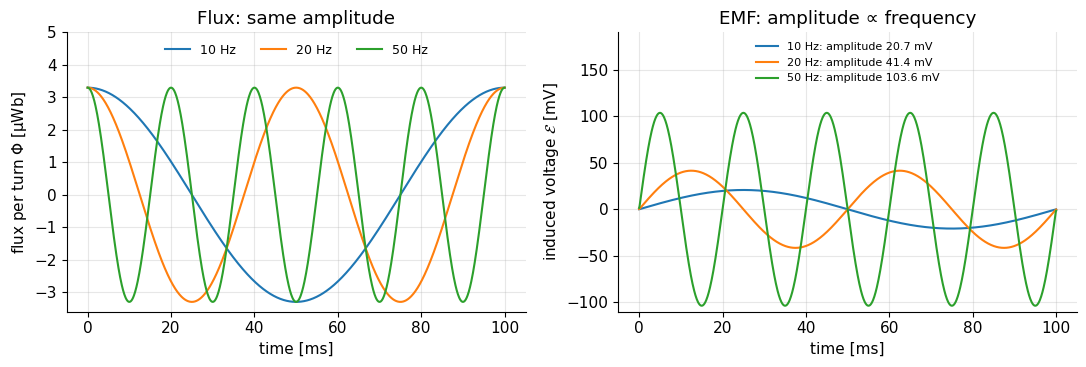

In [2]:
def dipole_field(points, m):
    """Field [T] of a point magnetic dipole m [A m^2] located at the origin, at points (..., 3) [m]."""
    r = np.linalg.norm(points, axis=-1, keepdims=True)
    e = points / r
    return mt.MU0 / (4 * np.pi) * (3 * e * np.sum(e * m, axis=-1, keepdims=True) - m) / r**3

a_coil, d_coil, n_turns = 0.05, 0.06, 100        # coil radius [m], distance from dipole [m], turns
# polar integration grid on the coil disk (the disk lies in the plane x = d_coil, normal along +x)
rho = (np.arange(60) + 0.5) / 60 * a_coil
phi = (np.arange(90) + 0.5) / 90 * 2 * np.pi
RHO, PHI = np.meshgrid(rho, phi)
disk_pts = np.stack([np.full_like(RHO, d_coil), RHO * np.cos(PHI), RHO * np.sin(PHI)], axis=-1)
dA = RHO * (a_coil / 60) * (2 * np.pi / 90)       # area element rho d(rho) d(phi) [m^2]

def flux_through_coil(m):
    """Flux [Wb] through one turn of the coil for dipole moment m (3,)."""
    return np.sum(dipole_field(disk_pts, m)[..., 0] * dA)

m0 = 1.0                                          # dipole moment [A m^2]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for f_rot in [10, 20, 50]:                        # rotation frequency [Hz] (a hand-cranked dynamo)
    w = 2 * np.pi * f_rot
    t = np.linspace(0, 0.1, 1001)                 # 100 ms
    Phi = np.array([flux_through_coil(m0 * np.array([np.cos(w * tt), -np.sin(w * tt), 0])) for tt in t])
    emf = -n_turns * np.gradient(Phi, t)          # Faraday: EMF = -N dPhi/dt
    axs[0].plot(t * 1e3, Phi * 1e6, label=f"{f_rot} Hz")
    axs[1].plot(t * 1e3, emf * 1e3, label=f"{f_rot} Hz: amplitude {emf.max() * 1e3:.1f} mV")
axs[0].set_xlabel("time [ms]"); axs[0].set_ylabel(r"flux per turn $\Phi$ [µWb]"); axs[0].set_title("Flux: same amplitude")
axs[1].set_xlabel("time [ms]"); axs[1].set_ylabel(r"induced voltage $\mathcal{E}$ [mV]"); axs[1].set_title("EMF: amplitude ∝ frequency")
axs[0].legend(loc="upper center", ncol=3, fontsize=9); axs[1].legend(loc="upper center", ncol=1, fontsize=8)
axs[0].set_ylim(-3.6, 5); axs[1].set_ylim(-110, 190); plt.tight_layout(); plt.show()

The flux (left) has the same amplitude at every rotation speed, but the induced voltage (right) is 2× larger at 20 Hz and 5× larger at 50 Hz than at 10 Hz: **$\mathcal E\propto\omega$**. Note also the 90° phase shift: the voltage peaks when the flux is changing fastest (passing through zero), a direct consequence of the derivative.

### How big is the MRI signal?

The formula $\mathcal E_{max} = N_{turns}\,\Phi_{max}\,\omega$ carries over directly. The "magnet" is now the magnetization of a piece of tissue, $m_0 = M_0 V_{vox}$, rotating at $\omega_0=\gamma B_0$; and (as we will show in section 9) $\Phi_{max} = \hat B_1\, m_0$, where $\hat B_1$ is the field the coil would make per ampere at the tissue location. So after a 90° excitation

$$\mathcal E_{max} \approx \omega_0\,\hat B_1\,M_0\,V_{vox}.$$

In words: signal voltage = precession frequency × coil sensitivity × magnetic moment of the tissue.
Where: $M_0\approx 9.3\times10^{-3}$ A/m for water at 3 T (derived in [RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb)), $V_{vox}$ = volume [m³], $\hat B_1$ [T/A] = transverse field per ampere of a single-turn receive coil.

In [3]:
B0 = 3.0
w0 = mt.GAMMA * B0                                 # Larmor angular frequency [rad/s]
M0 = 6.69e28 * mt.GAMMA**2 * mt.HBAR**2 * B0 / (4 * mt.K_BOLTZMANN * 310)   # water at 310 K [A/m] (see RP4)
a, d = 0.05, 0.05                                  # single-turn receive loop: radius 5 cm, tissue 5 cm away on axis
B1hat = mt.loop_field_on_axis(d, a, 1.0)           # coil field per ampere at the tissue [T/A]
print(f"f0 = {w0 / 2 / np.pi / 1e6:.1f} MHz, M0 = {M0 * 1e3:.2f} mA/m, coil sensitivity = {B1hat * 1e6:.2f} uT/A")
for label, V in [("1 mm^3 voxel", 1e-9), ("1 mL (1 cm^3)", 1e-6), ("10 mL", 1e-5)]:
    emf = w0 * B1hat * M0 * V
    print(f"  {label:14s}: peak signal ~ {emf * 1e9:10.0f} nV  = {emf * 1e6:8.3f} uV")

# for comparison: thermal (Johnson) noise voltage sqrt(4 k_B T R df) of a body-loaded coil
R_coil, df = 2.0, 100e3                            # effective resistance [Ohm] (mostly from the patient), bandwidth [Hz]
print(f"thermal noise over {df / 1e3:.0f} kHz bandwidth with R = {R_coil} Ohm: "
      f"{np.sqrt(4 * mt.K_BOLTZMANN * 310 * R_coil * df) * 1e9:.0f} nV rms")

f0 = 127.7 MHz, M0 = 9.33 mA/m, coil sensitivity = 4.44 uT/A
  1 mm^3 voxel  : peak signal ~         33 nV  =    0.033 uV
  1 mL (1 cm^3) : peak signal ~      33269 nV  =   33.269 uV
  10 mL         : peak signal ~     332695 nV  =  332.695 uV
thermal noise over 100 kHz bandwidth with R = 2.0 Ohm: 59 nV rms


So a single cubic millimetre of tissue gives only **tens of nanovolts**, and a few millilitres close to the coil give **tens to hundreds of microvolts**; the thermal noise of the coil plus patient is similar to the single-voxel signal. That is why receive coils must sit close to the body, why the first amplifier must add almost no noise, and why an image needs many samples (each sample contains signal from *all* voxels; averaging over the readout recovers the per-voxel SNR) — see [Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb).

> **🧭 Intuition — why higher $B_0$ gives more signal:** the induced voltage is ∝ $\omega_0$ (faster rotation) **and** the magnetization is ∝ $B_0$ (stronger polarization, [RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb)). So the signal voltage grows ∝ $B_0^2$. In the human body the noise also grows, roughly ∝ $B_0$ (the patient's conducting tissue is the dominant noise source and its losses grow with frequency), so the **SNR grows roughly ∝ $B_0$**. Going from 1.5 T to 3 T roughly doubles the SNR ([G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb), [Advanced SNR](../pass2_deep_dive/J4_Advanced_SNR.ipynb)).

## 4. AC signals and phasors (just enough)

A sinusoidal voltage is described by three numbers:

$$v(t) = V_0\cos(\omega t+\varphi) = \mathrm{Re}\{\hat V e^{i\omega t}\},\qquad \hat V = V_0e^{i\varphi}.$$

In words: amplitude $V_0$ [V] (how big), angular frequency $\omega=2\pi f$ [rad/s] (how fast), phase $\varphi$ [rad] (where in its cycle it starts). The complex number $\hat V$, the **phasor**, packs amplitude and phase together; the factor $e^{i\omega t}$ is common to every signal in a circuit driven at frequency $\omega$ and can be left out.

Why bother? Because derivatives become multiplications: $\frac{d}{dt}e^{i\omega t} = i\omega\,e^{i\omega t}$. That turns circuit differential equations into algebra with complex **impedances** $Z = \hat V/\hat I$:

| Element | Time domain | Impedance $Z$ | Behaviour |
|---|---|---|---|
| resistor $R$ | $v = R\,i_c$ | $R$ | frequency-independent, dissipates energy |
| inductor $L$ (a coil) | $v = L\,di_c/dt$ (Faraday!) | $i\omega L$ | blocks high frequencies |
| capacitor $C$ | $i_c = C\,dv/dt$ | $1/(i\omega C)$ | blocks low frequencies |

(here $i_c(t)$ is the current as function of time; $\hat I$ its phasor.)

> **⚠️ Common confusion:** Electrical engineers write $j=\sqrt{-1}$ and $e^{j\omega t}$. MRI physicists write $i$, and in this series precession is written $M_{xy}(t)=M_{xy}(0)e^{-i\omega t}$ (clockwise rotation). Both are conventions about how to write a real signal as the real part of a complex one; nothing physical depends on them, but signs flip when you mix sources. See [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb).

## 5. The electromagnetic spectrum: what "RF" means

Electromagnetic waves are oscillating electric and magnetic fields travelling at $c = 3\times10^8$ m/s. Frequency and wavelength are linked by $\lambda = c/f$, and each quantum (photon) carries energy $E_{ph} = hf$. Let us place MRI on the spectrum.

In [4]:
c, h, eV = 2.998e8, mt.H_PLANCK, 1.602e-19
spectrum = [
    ("mains electricity",              50.0),
    ("MRI gradient switching (~1 kHz)", 1e3),
    ("MRI 1.5 T (1H Larmor)",          mt.larmor_frequency(1.5)),
    ("FM radio",                        100e6),
    ("MRI 3 T",                         mt.larmor_frequency(3.0)),
    ("MRI 7 T",                         mt.larmor_frequency(7.0)),
    ("mobile phone",                    1.8e9),
    ("microwave oven / WiFi",           2.45e9),
    ("visible light (green)",           5.6e14),
    ("medical X-ray (~50 keV)",         1.2e19),
]
print(f"{'source':34s} {'frequency':>12s} {'wavelength':>12s} {'photon energy':>14s}")
for name, f in spectrum:
    lam = c / f
    lam_s = f"{lam / 1e3:.0f} km" if lam > 1e4 else (f"{lam:.2f} m" if lam > 1e-2 else f"{lam:.1e} m")
    print(f"{name:34s} {f:12.3e} {lam_s:>12s} {h * f / eV:11.1e} eV")
print("\nenergy needed to ionize a water molecule ~ 12.6 eV;  thermal energy k_B T at 310 K = "
      f"{mt.K_BOLTZMANN * 310 / eV:.3f} eV")

source                                frequency   wavelength  photon energy
mains electricity                     5.000e+01      5996 km     2.1e-13 eV
MRI gradient switching (~1 kHz)       1.000e+03       300 km     4.1e-12 eV
MRI 1.5 T (1H Larmor)                 6.387e+07       4.69 m     2.6e-07 eV
FM radio                              1.000e+08       3.00 m     4.1e-07 eV
MRI 3 T                               1.277e+08       2.35 m     5.3e-07 eV
MRI 7 T                               2.980e+08       1.01 m     1.2e-06 eV
mobile phone                          1.800e+09       0.17 m     7.4e-06 eV
microwave oven / WiFi                 2.450e+09       0.12 m     1.0e-05 eV
visible light (green)                 5.600e+14    5.4e-07 m     2.3e+00 eV
medical X-ray (~50 keV)               1.200e+19    2.5e-11 m     5.0e+04 eV

energy needed to ionize a water molecule ~ 12.6 eV;  thermal energy k_B T at 310 K = 0.027 eV


**Radio frequency (RF)** is the band of roughly kHz to hundreds of MHz (up to ~GHz), used for broadcasting. MRI Larmor frequencies (64 MHz at 1.5 T, 128 MHz at 3 T, 298 MHz at 7 T) sit right next to FM radio and TV bands.

* **Non-ionizing:** an MRI photon carries ~$5\times10^{-7}$ eV, about 10 million times less than needed to break a chemical bond or ionize a molecule, and even far below thermal energy. RF cannot damage DNA the way X-rays can; its only established biological effect is **heating** (section 8).
* **🔧 Engineering reality:** because the MRI signal (nV–µV) is at broadcast frequencies, the scanner room is a **Faraday cage** (copper or steel RF shielding, with filtered feed-throughs and a wave-guide for tubes). A door left ajar lets in FM/TV stations and walkie-talkies as bright lines ("zipper/spike artifacts") in the image ([Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb)).

## 6. LC resonance: the heart of every RF coil

An inductor (coil, $L$) stores energy in its magnetic field; a capacitor ($C$) stores energy in its electric field. Connected together, energy sloshes back and forth between them, like a mass on a spring, at the **resonance frequency**

$$f_0 = \frac{1}{2\pi\sqrt{LC}}.$$

In words: a coil plus a capacitor form a natural oscillator; bigger $L$ or $C$ → lower frequency.
Where: $f_0$ = resonance frequency [Hz], $L$ = inductance [H], $C$ = capacitance [F]. (Here $f_0$ denotes the circuit's resonance; an MRI coil is tuned so that it equals the Larmor frequency.)

<details><summary><b>📐 Derivation via impedance (optional)</b></summary>

For a resistor, inductor and capacitor in series, driven by a sinusoidal voltage $\hat V$, the impedances add:

$$Z(\omega) = R + i\omega L + \frac{1}{i\omega C} = R + i\left(\omega L - \frac{1}{\omega C}\right), \qquad \hat I = \frac{\hat V}{Z}.$$

The imaginary part vanishes when $\omega L = 1/(\omega C)$, i.e. $\omega_0 = 1/\sqrt{LC}$. There $|Z|$ is smallest ($=R$) and the current is largest: the inductor's and capacitor's reactances cancel. Defining the **quality factor**

$$Q = \frac{\omega_0 L}{R} = \frac{1}{R}\sqrt{\frac{L}{C}},$$

one can rewrite $Z = R\left[1 + iQ\left(\frac{\omega}{\omega_0}-\frac{\omega_0}{\omega}\right)\right]$, so the normalized current is

$$\frac{|\hat I(\omega)|}{|\hat I(\omega_0)|} = \frac{1}{\sqrt{1+Q^2\left(\frac{\omega}{\omega_0}-\frac{\omega_0}{\omega}\right)^2}}.$$

Power $\propto|\hat I|^2$ drops to half when $Q(\omega/\omega_0-\omega_0/\omega)=\pm1$, which for large $Q$ happens at $\omega\approx\omega_0(1\pm\frac{1}{2Q})$. Hence the full width at half power is $\Delta f = f_0/Q$.

</details>

**Quality factor** $Q = \omega_0L/R$: the ratio of energy stored to energy lost per cycle (×2π). A high-$Q$ circuit rings for about $Q/\pi$ cycles before its amplitude falls to $1/e$, and responds only in a narrow **bandwidth**

$$\Delta f = \frac{f_0}{Q}.$$

In words: the sharper the resonance (higher $Q$), the narrower the band of frequencies it responds to. Where: $\Delta f$ = full width at half maximum power [Hz], $R$ = total series resistance [Ω] (wire losses + losses in the patient).

Typical numbers: a 10 cm single-loop receive coil has $L\approx0.25$ µH, so for 127.7 MHz it needs $C\approx6$ pF.

tuning capacitor for 127.7 MHz with L = 0.25 uH: C = 6.21 pF


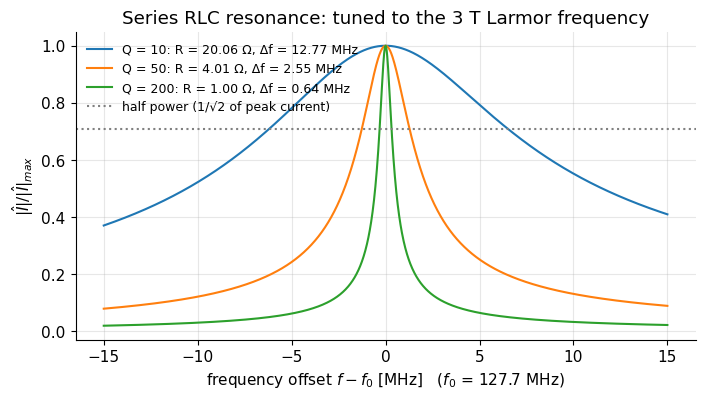

In [5]:
L = 0.25e-6                           # inductance of a ~10 cm loop [H]
f0 = mt.larmor_frequency(3.0)         # tune to 3 T Larmor frequency [Hz]
C = 1 / ((2 * np.pi * f0)**2 * L)     # from f0 = 1/(2 pi sqrt(LC))
print(f"tuning capacitor for {f0 / 1e6:.1f} MHz with L = {L * 1e6:.2f} uH: C = {C * 1e12:.2f} pF")

f = np.linspace(f0 - 15e6, f0 + 15e6, 2001)
w, w0 = 2 * np.pi * f, 2 * np.pi * f0
plt.figure(figsize=(8, 4))
for Q in [10, 50, 200]:
    R = w0 * L / Q                                          # resistance giving this Q [Ohm]
    Z = R + 1j * (w * L - 1 / (w * C))                      # series RLC impedance
    I_norm = np.abs(1 / Z) / np.abs(1 / R)                  # current relative to its peak
    plt.plot((f - f0) / 1e6, I_norm, label=f"Q = {Q}: R = {R:.2f} Ω, Δf = {f0 / Q / 1e6:.2f} MHz")
plt.axhline(1 / np.sqrt(2), color="gray", ls=":", label="half power (1/√2 of peak current)")
plt.xlabel(r"frequency offset $f - f_0$ [MHz]   ($f_0$ = 127.7 MHz)")
plt.ylabel(r"$|\hat I|/|\hat I|_{max}$")
plt.title("Series RLC resonance: tuned to the 3 T Larmor frequency"); plt.legend(fontsize=9); plt.show()

All three circuits are tuned to the same $f_0$; higher $Q$ gives a sharper peak and a narrower bandwidth ($Q=200$: 0.6 MHz). An MRI receive coil with $Q\approx50$ has a bandwidth of a few MHz — wide enough for the ±250 kHz imaging bandwidth, narrow enough to reject much out-of-band interference.

> **🔧 Engineering reality:** An unloaded surface coil may have $Q\approx200$–500; placed on a patient it drops to ≈ 20–80, because the conductive body adds resistance (it absorbs energy from the coil — and contributes thermal noise). A high ratio $Q_{unloaded}/Q_{loaded}$ means the noise comes mostly from the patient, as it should. Real coils also need **matching** networks (to transform the coil impedance to the 50 Ω of cables and preamplifiers), **detuning** circuits (PIN diodes that switch receive coils off during the powerful transmit pulse), and capacitors distributed around the loop. Coil arrays and the **birdcage** body coil are resonant structures of many LC elements. See [RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb).

### 🎛️ Try it yourself

Vary $Q$ and the detuning of the coil (e.g. a patient load shifts the resonance) and see how much signal at the Larmor frequency survives. (Needs a live kernel; the static plot above shows the defaults.)

In [6]:
try:
    from ipywidgets import interact, FloatLogSlider, FloatSlider
    def _rlc(Q=50, detune_MHz=0.0):
        fr = f0 + detune_MHz * 1e6                          # actual resonance of the (detuned) coil
        Cr = 1 / ((2 * np.pi * fr)**2 * L)
        R = 2 * np.pi * fr * L / Q
        Z = R + 1j * (w * L - 1 / (w * Cr))
        plt.figure(figsize=(7, 3.5)); plt.plot((f - f0) / 1e6, np.abs(R / Z))
        Zl = R + 1j * (w0 * L - 1 / (w0 * Cr))
        plt.axvline(0, color="C3", ls="--", label=f"Larmor: {np.abs(R / Zl):.2f} of peak")
        plt.xlabel("f - f0 [MHz]"); plt.ylabel("relative current"); plt.legend(); plt.show()
    interact(_rlc, Q=FloatLogSlider(value=50, base=10, min=0.5, max=3), detune_MHz=FloatSlider(value=0, min=-5, max=5, step=0.1))
except ImportError:
    print("ipywidgets not available - use the static plot above.")

interactive(children=(FloatLogSlider(value=50.0, description='Q', max=3.0, min=0.5), FloatSlider(value=0.0, de…

## 7. Near field vs radiation, and the wavelength in tissue

An antenna (e.g. for FM radio) is designed to **radiate**: to launch a wave that carries energy far away. Close to any source, however — within about $\lambda/2\pi$ — the field is dominated by the **near field**, which looks like the static Biot–Savart field of [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb), just oscillating in time. At 128 MHz, $\lambda/2\pi\approx37$ cm in air: patients, coils and spins are all in each other's near field.

> **⚠️ Common confusion:** It is often said that "the body emits radio waves that the coil picks up". That is misleading. MRI reception is **near-field Faraday induction**, exactly like the rotating-dipole demo above: the precessing magnetization changes the flux through a nearby coil. The power actually *radiated* away by precessing nuclei is utterly negligible. The same is true for excitation: the RF coil's oscillating near field tips the spins.

But inside the body there is a complication: tissue is mostly water, with a high **relative permittivity** $\varepsilon_r$, which slows electromagnetic waves down by $\sqrt{\varepsilon_r}$. The wavelength in tissue is

$$\lambda_{tissue}\approx\frac{c}{f\sqrt{\varepsilon_r}}.$$

In words: in a water-like medium the RF wavelength is about 8–9 times shorter than in air. Where: $c=3\times10^8$ m/s, $f$ = RF frequency [Hz], $\varepsilon_r$ ≈ 50–80 for tissues at these frequencies (≈ 80 for pure water; we neglect the effect of conductivity, which shortens it a little more and damps the wave).

In [7]:
for B0 in [0.55, 1.5, 3.0, 7.0]:
    f_L = mt.larmor_frequency(B0)
    lam_air = c / f_L
    lam_t = [c / (f_L * np.sqrt(er)) for er in (80, 50)]
    print(f"B0 = {B0:4.2f} T, f0 = {f_L / 1e6:6.1f} MHz: lambda in air = {lam_air:5.2f} m, "
          f"in tissue = {lam_t[0] * 100:4.0f}-{lam_t[1] * 100:3.0f} cm  (half wavelength {lam_t[0] * 50:3.0f}-{lam_t[1] * 50:3.0f} cm)")

B0 = 0.55 T, f0 =   23.4 MHz: lambda in air = 12.80 m, in tissue =  143-181 cm  (half wavelength  72- 91 cm)
B0 = 1.50 T, f0 =   63.9 MHz: lambda in air =  4.69 m, in tissue =   52- 66 cm  (half wavelength  26- 33 cm)
B0 = 3.00 T, f0 =  127.7 MHz: lambda in air =  2.35 m, in tissue =   26- 33 cm  (half wavelength  13- 17 cm)
B0 = 7.00 T, f0 =  298.0 MHz: lambda in air =  1.01 m, in tissue =   11- 14 cm  (half wavelength   6-  7 cm)


At 1.5 T the tissue wavelength (~50 cm) is larger than a head or torso, so the RF field inside the body is fairly uniform. At 3 T ($\lambda_{tissue}\approx26$ cm) the body is about one wavelength across, and at 7 T ($\lambda_{tissue}\approx11$–14 cm) the head is *larger* than a wavelength. Waves reflected and superposed inside the body form **standing-wave patterns**: the transmit field $B_1^+$ is no longer homogeneous, giving "central brightening" in 7 T head images and dark shading in 3 T abdominal images. Fixes include dielectric pads, multi-channel **parallel transmission**, and RF pulses designed to be robust to $B_1^+$ errors ([RF System](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb), [RF Pulse Design](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb)).

## 8. Eddy currents: induction where you don't want it

Faraday's law does not need a wire: any conductor in a changing field gets an induced electric field and therefore circulating **eddy currents**, which (Lenz) oppose the change. For a uniform field changing at rate $dB/dt$, the induced electric field along a circle of radius $r$ follows from $\oint\vec E\cdot d\vec l = -d\Phi/dt$:

$$E\cdot2\pi r = \pi r^2\,\frac{dB}{dt}\quad\Rightarrow\quad E = \frac{r}{2}\,\frac{dB}{dt}.$$

In words: the induced electric field grows with the size of the conducting loop and with how fast the field changes. Where: $E$ = induced electric field [V/m], $r$ = radius of the current path [m], $dB/dt$ [T/s].

Three places this matters in MRI:

1. **Eddy currents in the scanner's metal** (cryostat, RF shield): switching a gradient induces currents in the magnet's metal structures that create their own field opposing the gradient, distorting the gradient waveform (→ image artifacts). Countermeasures: actively shielded gradient coils and **pre-emphasis** of the drive current ([Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb)).
2. **Nerve stimulation:** fast gradient switching induces electric fields in the body that can stimulate peripheral nerves (PNS: tingling, twitching). This, not the amplifier, often limits the slew rate.
3. **RF heating:** the RF field oscillates at ~10⁸ Hz, so $dB/dt$ is huge; the induced currents in conductive tissue dissipate power — measured as **SAR** (specific absorption rate).

In [8]:
# (2) gradient-induced E field: dB/dt at distance z from the isocentre is SR * z
SR, z_pos, r_body = 200.0, 0.25, 0.15      # slew rate [T/m/s], distance from isocentre [m], radius of current loop [m]
dBdt = SR * z_pos
print(f"gradients: dB/dt = {dBdt:.0f} T/s at {z_pos * 100:.0f} cm -> E ~ {r_body / 2 * dBdt:.1f} V/m in a "
      f"{r_body * 100:.0f} cm radius loop (nerve-stimulation thresholds are a few V/m)")

# (3) RF heating: B1(t) = B1 cos(w t)  -> |dB/dt| up to w*B1
sigma_el, rho_t, r_rf = 0.5, 1000.0, 0.10  # conductivity [S/m], density [kg/m^3], radius [m]
for B0 in [1.5, 3.0]:
    w_L = mt.GAMMA * B0
    B1 = 10e-6                              # RF amplitude [T] (same flip angle needs the same B1 at any B0)
    E_peak = r_rf / 2 * w_L * B1              # quasi-static estimate [V/m]
    sar_on = sigma_el * (E_peak**2 / 2) / rho_t        # SAR = sigma |E_rms|^2 / rho, E_rms^2 = E_peak^2 / 2
    print(f"RF at {B0} T: E ~ {E_peak:.0f} V/m peak, SAR while the pulse is on ~ {sar_on:.0f} W/kg, "
          f"averaged over a 5% RF duty cycle ~ {0.05 * sar_on:.1f} W/kg")

gradients: dB/dt = 50 T/s at 25 cm -> E ~ 3.8 V/m in a 15 cm radius loop (nerve-stimulation thresholds are a few V/m)
RF at 1.5 T: E ~ 201 V/m peak, SAR while the pulse is on ~ 10 W/kg, averaged over a 5% RF duty cycle ~ 0.5 W/kg
RF at 3.0 T: E ~ 401 V/m peak, SAR while the pulse is on ~ 40 W/kg, averaged over a 5% RF duty cycle ~ 2.0 W/kg


These crude estimates land exactly where the safety limits are: a few V/m from gradients (≈ PNS threshold) and ~W/kg time-averaged from RF (whole-body limit 2 W/kg). Because $E\propto\omega B_1$, **SAR ∝ $B_0^2$** for the same flip angle: going from 1.5 T to 3 T quadruples RF heating, which is why many high-field protocols are SAR-limited ([MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb)). (The real E-field distribution in a body is non-uniform and needs electromagnetic simulation; these numbers are order-of-magnitude only.)

## 9. Reciprocity: a good transmitter is a good receiver

The **principle of reciprocity** says, for MRI purposes:

> The flux that a small magnet $\vec m$ at position $\vec r$ produces through a coil equals $\hat{\vec B}_1(\vec r)\cdot\vec m$, where $\hat{\vec B}_1(\vec r)$ is the field the **same coil** would produce at $\vec r$ if you drove it with 1 A.

$$\Phi = \hat{\vec B}_1(\vec r)\cdot\vec m, \qquad \mathcal E = -\frac{d}{dt}\left(\hat{\vec B}_1(\vec r)\cdot\vec m(t)\right).$$

In words: to know how well a coil *hears* a spot, compute how strongly it would *shout* at that spot. Where: $\hat{\vec B}_1$ [T/A] = coil field per unit current, $\vec m$ [A m²] = magnetic moment at $\vec r$, $\Phi$ [Wb] = flux through (one turn of) the coil.

Intuition: the coil's field lines show which paths "connect" the coil to each point; a magnet sitting where many of the coil's field lines pass, and aligned with them, pushes its own field lines through the coil. Let us verify it with our rotating-dipole demo: the flux computed by integrating the dipole field over the coil area must equal $\hat{\vec B}_1(\text{origin})\cdot\vec m$, where $\hat{\vec B}_1$ comes from Biot–Savart (`mt.loop_coil_field`).

In [9]:
# coil field per ampere at the dipole position (origin): loop of radius a_coil centred at x = d_coil, axis along x
B1hat_vec = mt.loop_coil_field(np.zeros(3), radius=a_coil, current=1.0, center=(d_coil, 0, 0), normal="x")
print("coil field per ampere at the dipole:", np.round(B1hat_vec * 1e6, 3), "uT/A")
for ang in [0, 30, 60, 90]:
    m = m0 * np.array([np.cos(np.deg2rad(ang)), -np.sin(np.deg2rad(ang)), 0])
    print(f"dipole at {ang:2d} deg: flux by area integral = {flux_through_coil(m) * 1e6:.4f} uWb,"
          f"  reciprocity B1hat.m = {B1hat_vec @ m * 1e6:.4f} uWb")

coil field per ampere at the dipole: [ 3.297  0.    -0.   ] uT/A
dipole at  0 deg: flux by area integral = 3.2973 uWb,  reciprocity B1hat.m = 3.2970 uWb
dipole at 30 deg: flux by area integral = 2.8555 uWb,  reciprocity B1hat.m = 2.8553 uWb
dipole at 60 deg: flux by area integral = 1.6486 uWb,  reciprocity B1hat.m = 1.6485 uWb
dipole at 90 deg: flux by area integral = 0.0000 uWb,  reciprocity B1hat.m = 0.0000 uWb


The two computations agree (to the accuracy of the numerical integration). Reciprocity turns a hard problem (integrate the spin's field over the coil) into an easy one (compute the coil's field at the spin), and it also defines the **receive sensitivity map** of a coil, written $B_1^-(\vec r)$ or $C_n(\vec r)$ for coil element $n$. A rotating transverse moment is "heard" through the part of $\hat{\vec B}_1$ perpendicular to $B_0$ (the $z$ part does not see a changing moment). Here is that sensitivity for a surface coil lying above an axial slice (the $x$–$y$ plane, perpendicular to $B_0$):

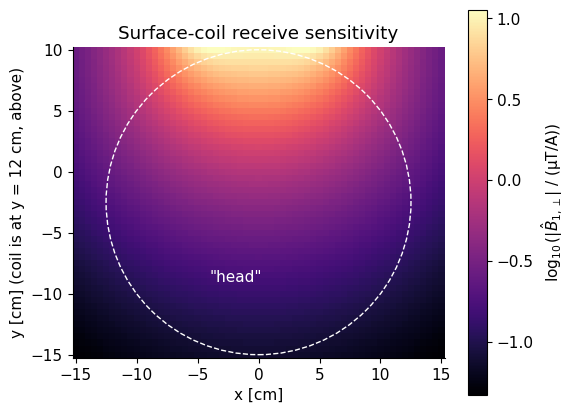

In [10]:
x = np.linspace(-0.15, 0.15, 61)
y = np.linspace(-0.15, 0.10, 51)
X, Y = np.meshgrid(x, y)
pts = np.stack([X, Y, np.zeros_like(X)], axis=-1)
# 10 cm diameter loop lying flat 12 cm above the centre (its axis is along y, i.e. perpendicular to B0 = z)
B1 = mt.loop_coil_field(pts, radius=0.05, current=1.0, center=(0, 0.12, 0), normal="y")
sens = np.hypot(B1[..., 0], B1[..., 1])           # transverse part of the coil field per ampere [T/A]
fig, ax = plt.subplots(figsize=(6, 5))
pc = ax.pcolormesh(X * 100, Y * 100, np.log10(sens * 1e6), shading="auto", cmap="magma")   # log scale
ax.add_patch(plt.Circle((0, -2.5), 12.5, fill=False, color="w", ls="--"))
ax.text(-4, -9, "\"head\"", color="w")
ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel("x [cm]"); ax.set_ylabel("y [cm] (coil is at y = 12 cm, above)")
ax.set_title("Surface-coil receive sensitivity")
plt.colorbar(pc, ax=ax, label=r"$\log_{10}(|\hat B_{1,\perp}|$ / (µT/A)$)$")
plt.show()

(Note the logarithmic colour scale: one unit = a factor of 10.) The sensitivity is high just under the coil and falls off steeply with depth — more than 20× weaker at the centre of the head than at its top — exactly why surface-coil images are bright near the coil and dark deep inside. Combining many such small coils with different sensitivity maps is the basis of **coil arrays** and **parallel imaging** ([Accelerated Imaging Methods](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)). Reciprocity also explains why a homogeneous *transmit* coil (the body birdcage) is a mediocre *receiver*: it is "far" from every point.

## Where this shows up in MRI

| Concept from this refresher | Where it is used |
|---|---|
| Faraday induction, signal ∝ ω0 M0, signal size, SNR ∝ B0 | [MRI Signal Equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb), [Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb), [Advanced SNR](../pass2_deep_dive/J4_Advanced_SNR.ipynb) |
| LC resonance, Q, bandwidth, tuning/matching, detuning, birdcage, arrays, near field | [RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb), [Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) |
| Reciprocity, coil sensitivity maps $B_1^-$, $C_n(\vec r)$ | [Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb), [Accelerated Imaging Methods](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) |
| Wavelength in tissue, standing waves, $B_1^+$ inhomogeneity | [RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb), [RF Pulse Design](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb) |
| Eddy currents, PNS, SAR ∝ B0² | [Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb), [MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| RF interference, Faraday cage | [Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb) |

## Key takeaways

* **Faraday:** a changing magnetic flux induces a voltage $\mathcal E=-N\,d\Phi/dt$; **Lenz:** the induced current opposes the change.
* A rotating magnet near a coil induces an AC voltage at the rotation frequency with amplitude ∝ ω. Precessing magnetization is such a magnet → the MRI signal: tens of nV per mm³, µV and more for larger volumes.
* Signal ∝ $\omega_0 M_0 \propto B_0^2$; with body noise ∝ $B_0$, SNR ∝ ~$B_0$.
* MRI works at **radio frequencies** (64–300 MHz), next to FM radio; RF photons are ~10⁷× too weak to ionize — the safety concern is heating (SAR ∝ $B_0^2$).
* Every RF coil is an LC resonator: $f_0 = 1/(2\pi\sqrt{LC})$, bandwidth $\Delta f = f_0/Q$; the patient lowers $Q$ (loading).
* MRI uses the **near field** (induction), not radiation; but at 3–7 T the wavelength in tissue (26 → ~12 cm) is comparable with the body, causing $B_1^+$ inhomogeneity.
* **Reciprocity:** a coil's receive sensitivity at a point equals its transmit field per ampere there.

## Check your understanding

1. A coil's flux is $\Phi(t) = \Phi_{max}\cos(\omega t)$. Write down the induced voltage. What is its amplitude, and how is it shifted relative to the flux?

<details><summary>Answer</summary>

$\mathcal E = -N\,d\Phi/dt = N\Phi_{max}\,\omega\sin(\omega t)$. Amplitude $N\Phi_{max}\omega$ (∝ frequency); it is shifted by a quarter period (90°): the voltage is largest when the flux passes through zero, i.e. when it changes fastest.

</details>

2. Why does doubling $B_0$ roughly quadruple the MRI signal voltage but only double the SNR in the body?

<details><summary>Answer</summary>

The magnetization $M_0\propto B_0$ (more polarization) and the induced voltage is ∝ $\omega_0 \propto B_0$ (faster precession), giving signal ∝ $B_0^2$. The noise, dominated by the patient's conductive losses, also grows ∝ ~$B_0$, so SNR ∝ ~$B_0$.

</details>

3. You need to tune a coil with $L = 0.4$ µH to 63.9 MHz (1.5 T). What capacitance do you need? If its loaded $Q$ is 40, what is its bandwidth?

<details><summary>Answer</summary>

$C = 1/((2\pi f_0)^2 L) = 1/((2\pi\cdot63.9\times10^6)^2\cdot0.4\times10^{-6})\approx15.5$ pF. Bandwidth $\Delta f = f_0/Q\approx1.6$ MHz.

</details>

4. Is the MRI signal "radio waves emitted by the body"? Explain.

<details><summary>Answer</summary>

Not really. It is the oscillating *near field* of the precessing magnetization inducing a voltage in a coil a few cm away (Faraday induction). The power radiated as propagating waves is negligible. The frequency is in the radio band, which is why "RF" is used.

</details>

5. Why does the RF transmit field become inhomogeneous in the head at 7 T but much less at 1.5 T?

<details><summary>Answer</summary>

The wavelength in tissue is ≈ $c/(f\sqrt{\varepsilon_r})$: ~11–14 cm at 298 MHz but ~50 cm at 64 MHz. At 7 T the head (~20 cm) spans more than a wavelength, so interference/standing-wave patterns form; at 1.5 T the head is small compared with the wavelength and the field is quasi-static and smooth.

</details>

6. Using reciprocity, explain why a small surface coil gives a higher SNR near the surface than the large body coil, but a lower SNR deep in the body.

<details><summary>Answer</summary>

Receive sensitivity at a point = the coil's field per ampere there. A small coil makes a strong field close to itself (high sensitivity near the surface, and it picks up noise only from a small volume) but its field falls off rapidly with depth. The body coil makes a weaker but uniform field everywhere, so its sensitivity is lower near the surface, but it does not fall off at depth.

</details>

---
*New refresher written for this adaptation; it expands the "Receiving Magnetic Resonance Signal" and "Reciprocity" sections of P. Larson, "Principles of MRI" (MIT License), chapter "Magnetic Fields in MRI" (original animation reused). The order-of-magnitude signal, noise, PNS and SAR estimates are new and approximate.*

*References:* D. J. Griffiths, *Introduction to Electrodynamics* (Cambridge Univ. Press), ch. 7 (Faraday induction) · D. I. Hoult & R. E. Richards, "The signal-to-noise ratio of the nuclear magnetic resonance experiment", *J. Magn. Reson.* 24, 71–85 (1976) · D. I. Hoult, "The principle of reciprocity in signal strength calculations — a mathematical guide", *Concepts Magn. Reson.* 12, 173–187 (2000) · J. Jin, *Electromagnetic Analysis and Design in Magnetic Resonance Imaging* (CRC Press) · D. W. McRobbie et al., *MRI from Picture to Proton* (Cambridge Univ. Press) · IEC 60601-2-33 (safety limits for MR equipment).